In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


In [2]:
# ── SCIKIT-LEARN: MODEL SELECTION ─────────────────────
from sklearn.model_selection import train_test_split

# ── SCIKIT-LEARN: PREPROCESSING ───────────────────────
from sklearn.preprocessing import StandardScaler

# ── SCIKIT-LEARN: REGRESSION MODELS ───────────────────
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

# ── SCIKIT-LEARN: CLASSIFICATION MODELS ───────────────
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

In [3]:
import pandas as pd

# Load the three datasets
nykaa = pd.read_csv("nykaa_campaign_data_with_nulls.csv")
purplle = pd.read_csv("purplle_campaign_data_with_nulls.csv")
tira = pd.read_csv("tira_campaign_data_with_nulls.csv")

# Combine all three datasets
df = pd.concat(
    [nykaa, purplle, tira],
    ignore_index=True
)

print("All three datasets combined successfully!")


All three datasets combined successfully!


In [4]:
df.to_csv("marketing_campaign_combined.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [5]:
df.shape

(166665, 16)

In [6]:
print(df.shape)

(166665, 16)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166665 entries, 0 to 166664
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Campaign_ID       161248 non-null  object 
 1   Campaign_Type     158307 non-null  object 
 2   Target_Audience   158493 non-null  object 
 3   Duration          158342 non-null  float64
 4   Channel_Used      158383 non-null  object 
 5   Impressions       158441 non-null  float64
 6   Clicks            158441 non-null  float64
 7   Leads             158575 non-null  float64
 8   Conversions       158665 non-null  float64
 9   Revenue           158361 non-null  float64
 10  Acquisition_Cost  158504 non-null  float64
 11  ROI               158367 non-null  float64
 12  Language          158366 non-null  object 
 13  Engagement_Score  158584 non-null  float64
 14  Customer_Segment  158490 non-null  object 
 15  Date              158566 non-null  object 
dtypes: float64(9), objec

In [8]:
df.describe()

,Duration,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Engagement_Score
count,158342.000000,158441.000000,158441.000000,158575.000000,158665.000000,1.583610e+05,158504.000000,158367.00000,158584.000000
mean,17.488582,55068.759456,4684.973978,1872.167157,1028.498213,5.138267e+05,376.830560,2.69620,13.764843
std,7.501765,25961.688169,3177.355919,1430.272768,857.687806,4.875933e+05,536.701697,4.48544,6.328162
min,5.000000,10001.000000,202.000000,48.000000,17.000000,3.895000e+03,8.180000,-0.99000,2.560000
25%,11.000000,32599.000000,2110.000000,779.000000,401.000000,1.775800e+05,106.760000,0.05000,8.380000
50%,17.000000,55113.000000,3908.000000,1476.000000,775.000000,3.588720e+05,208.725000,1.24000,13.590000
75%,24.000000,77582.000000,6695.000000,2600.000000,1403.000000,6.856400e+05,428.560000,3.58000,18.790000
max,30.000000,100000.000000,14944.000000,8876.000000,6686.000000,4.579910e+06,15473.160000,79.30000,30.990000


In [9]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 128507


In [10]:
df.isnull().sum()

Campaign_ID         5417
Campaign_Type       8358
Target_Audience     8172
Duration            8323
Channel_Used        8282
Impressions         8224
Clicks              8224
Leads               8090
Conversions         8000
Revenue             8304
Acquisition_Cost    8161
ROI                 8298
Language            8299
Engagement_Score    8081
Customer_Segment    8175
Date                8099
dtype: int64

features

In [11]:
print("Number of features:", df.shape[1])
print("Column names:", df.columns.tolist())

Number of features: 16
Column names: ['Campaign_ID', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Impressions', 'Clicks', 'Leads', 'Conversions', 'Revenue', 'Acquisition_Cost', 'ROI', 'Language', 'Engagement_Score', 'Customer_Segment', 'Date']


In [12]:
df.head()

,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
0,NY-CMP-1000,Social Media,College Students,21.0,"WhatsApp, YouTube",57804.0,6156.0,3616.0,2355.0,1867515.0,NaN,6.14,Hindi,20.98,College Students,29-04-2025
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18.0,YouTube,91801.0,3321.0,1971.0,1357.0,1046247.0,180.83,3.26,Hindi,7.24,College Students,06-04-2025
2,NY-CMP-1002,Influencer,Youth,23.0,"WhatsApp, Google, YouTube",15536.0,2182.0,952.0,755.0,197055.0,90.60,NaN,English,25.03,College Students,14-01-2025
3,NY-CMP-1003,Email,Working Women,18.0,"YouTube, Facebook, Instagram",88114.0,8413.0,2231.0,947.0,376906.0,249.07,0.60,Hindi,13.15,NaN,04-06-2025
4,NY-CMP-1004,Paid Ads,College Students,10.0,"Facebook, Instagram",96871.0,3743.0,2060.0,1258.0,518296.0,228.60,0.80,Hindi,7.29,Tier 2 City Customers,29-12-2024


In [13]:
market_predict=df.copy()
market_predict


,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
0,NY-CMP-1000,Social Media,College Students,21.0,"WhatsApp, YouTube",57804.0,6156.0,3616.0,2355.0,1867515.0,NaN,6.14,Hindi,20.98,College Students,29-04-2025
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18.0,YouTube,91801.0,3321.0,1971.0,1357.0,1046247.0,180.83,3.26,Hindi,7.24,College Students,06-04-2025
2,NY-CMP-1002,Influencer,Youth,23.0,"WhatsApp, Google, YouTube",15536.0,2182.0,952.0,755.0,197055.0,90.60,NaN,English,25.03,College Students,14-01-2025
3,NY-CMP-1003,Email,Working Women,18.0,"YouTube, Facebook, Instagram",88114.0,8413.0,2231.0,947.0,376906.0,249.07,0.60,Hindi,13.15,NaN,04-06-2025
4,NY-CMP-1004,Paid Ads,College Students,10.0,"Facebook, Instagram",96871.0,3743.0,2060.0,1258.0,518296.0,228.60,0.80,Hindi,7.29,Tier 2 City Customers,29-12-2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166660,NaN,NaN,Tier 2 City Customers,11.0,"Instagram, YouTube, Email",NaN,3799.0,NaN,1099.0,454986.0,213.21,0.94,Bengali,10.70,Youth,12-11-2024
166661,TI-CMP-56551,SEO,Working Women,20.0,"Google, Instagram",54886.0,1578.0,634.0,NaN,136514.0,436.24,-0.09,English,4.66,Working Women,25-08-2024
166662,TI-CMP-56552,Email,NaN,13.0,"Facebook, Instagram",97954.0,11480.0,4567.0,2144.0,445952.0,78.77,1.64,NaN,18.57,Premium Shoppers,15-04-2025
166663,NaN,Influencer,Premium Shoppers,22.0,"Google, Email",11669.0,NaN,122.0,44.0,26884.0,NaN,-0.76,English,5.35,Working Women,21-07-2024


In [14]:
market_predict.shape

(166665, 16)

In [15]:
market_predict.info

<bound method DataFrame.info of          Campaign_ID Campaign_Type        Target_Audience  Duration  \
0        NY-CMP-1000  Social Media       College Students      21.0   
1        NY-CMP-1001      Paid Ads  Tier 2 City Customers      18.0   
2        NY-CMP-1002    Influencer                  Youth      23.0   
3        NY-CMP-1003         Email          Working Women      18.0   
4        NY-CMP-1004      Paid Ads       College Students      10.0   
...              ...           ...                    ...       ...   
166660           NaN           NaN  Tier 2 City Customers      11.0   
166661  TI-CMP-56551           SEO          Working Women      20.0   
166662  TI-CMP-56552         Email                    NaN      13.0   
166663           NaN    Influencer       Premium Shoppers      22.0   
166664  TI-CMP-56554      Paid Ads          Working Women       NaN   

                        Channel_Used  Impressions   Clicks   Leads  \
0                  WhatsApp, YouTube      578

In [16]:
market_predict.isnull().sum()

Campaign_ID         5417
Campaign_Type       8358
Target_Audience     8172
Duration            8323
Channel_Used        8282
Impressions         8224
Clicks              8224
Leads               8090
Conversions         8000
Revenue             8304
Acquisition_Cost    8161
ROI                 8298
Language            8299
Engagement_Score    8081
Customer_Segment    8175
Date                8099
dtype: int64

In [17]:
market_predict["Revenue"]=market_predict["Revenue"].fillna(0)
market_predict["Revenue"].isnull().sum()

np.int64(0)

In [18]:
mean_val = market_predict['Acquisition_Cost'].mean()
market_predict['Acquisition_Cost'] = market_predict['Acquisition_Cost'].fillna(mean_val)
market_predict[market_predict['Acquisition_Cost'].isnull()]
print(f"✅ Acquisition_Cost → filled with mean: {mean_val:.2f}")

✅ Acquisition_Cost → filled with mean: 376.83


In [19]:
market_predict['Customer_Segment'] = market_predict['Customer_Segment'].fillna(
    market_predict['Customer_Segment'].mode()[0]
)
market_predict['Language'] = market_predict['Language'].fillna(
    market_predict['Language'].mode()[0]
)

In [20]:
categorical_cols = ['Campaign_Type', 'Target_Audience',
                    'Channel_Used']
for col in categorical_cols:
    mode_val = market_predict[col].mode()[0]
    market_predict[col] = market_predict[col].fillna(mode_val)
    
    print(f"✅ {col} → filled with mode: {mode_val}")

✅ Campaign_Type → filled with mode: Influencer
✅ Target_Audience → filled with mode: Premium Shoppers
✅ Channel_Used → filled with mode: Email


In [21]:
numerical_cols = ['Duration', 'Impressions', 'Clicks', 'Leads', 
                  'Conversions', 'Engagement_Score']

for col in numerical_cols:
    median_val = market_predict[col].median()
    market_predict[col] = market_predict[col].fillna(median_val)
    print(f"✅ {col} → filled with median: {median_val:.2f}")

✅ Duration → filled with median: 17.00
✅ Impressions → filled with median: 55113.00
✅ Clicks → filled with median: 3908.00
✅ Leads → filled with median: 1476.00
✅ Conversions → filled with median: 775.00
✅ Engagement_Score → filled with median: 13.59


In [22]:
market_predict.isnull().sum()

Campaign_ID         5417
Campaign_Type          0
Target_Audience        0
Duration               0
Channel_Used           0
Impressions            0
Clicks                 0
Leads                  0
Conversions            0
Revenue                0
Acquisition_Cost       0
ROI                 8298
Language               0
Engagement_Score       0
Customer_Segment       0
Date                8099
dtype: int64

ck duplicate

In [23]:
market_predict.duplicated().sum()

np.int64(0)

introduce ROI COLUMN

In [24]:
market_predict['Updated_ROI'] = (
    (market_predict['Revenue'] - market_predict['Acquisition_Cost'])
    / market_predict['Acquisition_Cost']
).round(2)
market_predict.head(2)

,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date,Updated_ROI
0,NY-CMP-1000,Social Media,College Students,21.0,"WhatsApp, YouTube",57804.0,6156.0,3616.0,2355.0,1867515.0,376.83056,6.14,Hindi,20.98,College Students,29-04-2025,4954.85
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18.0,YouTube,91801.0,3321.0,1971.0,1357.0,1046247.0,180.83000,3.26,Hindi,7.24,College Students,06-04-2025,5784.80


In [25]:
roi_pos = market_predict.columns.get_loc('ROI')
col = market_predict.pop('Updated_ROI')
market_predict.insert(roi_pos + 1, 'Updated_ROI', col)
market_predict.isnull().sum()

Campaign_ID         5417
Campaign_Type          0
Target_Audience        0
Duration               0
Channel_Used           0
Impressions            0
Clicks                 0
Leads                  0
Conversions            0
Revenue                0
Acquisition_Cost       0
ROI                 8298
Updated_ROI            0
Language               0
Engagement_Score       0
Customer_Segment       0
Date                8099
dtype: int64

In [26]:
market_predict['ROI'] = market_predict['ROI'].fillna('0.00')

In [27]:
# Cell 1 — Find unique channels
all_channels = (
    market_predict['Channel_Used'].str.split(',').explode().str.strip().unique())

sorted(all_channels)
print("Total unique channels:", len(all_channels))
sorted

Total unique channels: 6


<function sorted(iterable, /, *, key=None, reverse=False)>

In [28]:
channel_dummies = market_predict['Channel_Used'].str.get_dummies(sep=', ')
channel_dummies
channel_dummies.columns.tolist()

['Email', 'Facebook', 'Google', 'Instagram', 'WhatsApp', 'YouTube']

In [29]:
channel_pos = market_predict.columns.get_loc('Channel_Used')
for i, col in enumerate(channel_dummies.columns):
    market_predict.insert(channel_pos + 1 + i, col, channel_dummies[col])
market_predict.head(2)

,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Email,Facebook,Google,Instagram,WhatsApp,...,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Updated_ROI,Language,Engagement_Score,Customer_Segment,Date
0,NY-CMP-1000,Social Media,College Students,21.0,"WhatsApp, YouTube",0,0,0,0,1,...,3616.0,2355.0,1867515.0,376.83056,6.14,4954.85,Hindi,20.98,College Students,29-04-2025
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18.0,YouTube,0,0,0,0,0,...,1971.0,1357.0,1046247.0,180.83000,3.26,5784.80,Hindi,7.24,College Students,06-04-2025


In [30]:
market_predict.drop(columns=['Campaign_ID','ROI'],inplace=True)

In [31]:
market_predict

,Campaign_Type,Target_Audience,Duration,Channel_Used,Email,Facebook,Google,Instagram,WhatsApp,YouTube,...,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,Updated_ROI,Language,Engagement_Score,Customer_Segment,Date
0,Social Media,College Students,21.0,"WhatsApp, YouTube",0,0,0,0,1,1,...,6156.0,3616.0,2355.0,1867515.0,376.83056,4954.85,Hindi,20.98,College Students,29-04-2025
1,Paid Ads,Tier 2 City Customers,18.0,YouTube,0,0,0,0,0,1,...,3321.0,1971.0,1357.0,1046247.0,180.83000,5784.80,Hindi,7.24,College Students,06-04-2025
2,Influencer,Youth,23.0,"WhatsApp, Google, YouTube",0,0,1,0,1,1,...,2182.0,952.0,755.0,197055.0,90.60000,2174.00,English,25.03,College Students,14-01-2025
3,Email,Working Women,18.0,"YouTube, Facebook, Instagram",0,1,0,1,0,1,...,8413.0,2231.0,947.0,376906.0,249.07000,1512.25,Hindi,13.15,Youth,04-06-2025
4,Paid Ads,College Students,10.0,"Facebook, Instagram",0,1,0,1,0,0,...,3743.0,2060.0,1258.0,518296.0,228.60000,2266.26,Hindi,7.29,Tier 2 City Customers,29-12-2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166660,Influencer,Tier 2 City Customers,11.0,"Instagram, YouTube, Email",1,0,0,1,0,1,...,3799.0,1476.0,1099.0,454986.0,213.21000,2132.98,Bengali,10.70,Youth,12-11-2024
166661,SEO,Working Women,20.0,"Google, Instagram",0,0,1,1,0,0,...,1578.0,634.0,775.0,136514.0,436.24000,311.93,English,4.66,Working Women,25-08-2024
166662,Email,Premium Shoppers,13.0,"Facebook, Instagram",0,1,0,1,0,0,...,11480.0,4567.0,2144.0,445952.0,78.77000,5660.44,Hindi,18.57,Premium Shoppers,15-04-2025
166663,Influencer,Premium Shoppers,22.0,"Google, Email",1,0,1,0,0,0,...,3908.0,122.0,44.0,26884.0,376.83056,70.34,English,5.35,Working Women,21-07-2024


In [32]:
market_predict.isnull().sum()

Campaign_Type          0
Target_Audience        0
Duration               0
Channel_Used           0
Email                  0
Facebook               0
Google                 0
Instagram              0
WhatsApp               0
YouTube                0
Impressions            0
Clicks                 0
Leads                  0
Conversions            0
Revenue                0
Acquisition_Cost       0
Updated_ROI            0
Language               0
Engagement_Score       0
Customer_Segment       0
Date                8099
dtype: int64

In [33]:
null_count = market_predict['Date'].isnull().sum()
null_count

np.int64(8099)

In [34]:
import pandas as pd
import numpy as np

# Step 1: Convert Date column into datetime format
market_predict['Date'] = pd.to_datetime(
    market_predict['Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

# Step 2: Identify existing and missing dates
existing_dates = market_predict['Date'].dropna()
missing_count = market_predict['Date'].isnull().sum()

# Step 3: Generate random dates for missing values
if missing_count > 0 and len(existing_dates) > 0:
    random_dates = pd.to_datetime(
        np.random.choice(
            existing_dates.astype('int64').to_numpy(),
            size=missing_count,
            replace=True
        )
    )

    # Step 4: Fill missing dates
    market_predict.loc[
        market_predict['Date'].isnull(), 'Date'
    ] = random_dates

# Step 5: Verify the results
print("Missing dates:", market_predict['Date'].isnull().sum())
print("Minimum date:", market_predict['Date'].min())
print("Maximum date:", market_predict['Date'].max())
print("Dataset shape:", market_predict.shape)

# Step 6: Save cleaned dataset
market_predict.to_csv('Market_Predict_Cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")

Missing dates: 0
Minimum date: 2024-07-01 00:00:00
Maximum date: 2025-06-24 00:00:00
Dataset shape: (166665, 21)
Cleaned dataset saved successfully!


In [35]:
market_predict.drop(columns=['Channel_Used'], inplace=True)
market_predict.drop(columns=['Date'], inplace=True)

In [36]:
market_predict.isnull().sum()

Campaign_Type       0
Target_Audience     0
Duration            0
Email               0
Facebook            0
Google              0
Instagram           0
WhatsApp            0
YouTube             0
Impressions         0
Clicks              0
Leads               0
Conversions         0
Revenue             0
Acquisition_Cost    0
Updated_ROI         0
Language            0
Engagement_Score    0
Customer_Segment    0
dtype: int64

In [37]:
market_predict

,Campaign_Type,Target_Audience,Duration,Email,Facebook,Google,Instagram,WhatsApp,YouTube,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,Updated_ROI,Language,Engagement_Score,Customer_Segment
0,Social Media,College Students,21.0,0,0,0,0,1,1,57804.0,6156.0,3616.0,2355.0,1867515.0,376.83056,4954.85,Hindi,20.98,College Students
1,Paid Ads,Tier 2 City Customers,18.0,0,0,0,0,0,1,91801.0,3321.0,1971.0,1357.0,1046247.0,180.83000,5784.80,Hindi,7.24,College Students
2,Influencer,Youth,23.0,0,0,1,0,1,1,15536.0,2182.0,952.0,755.0,197055.0,90.60000,2174.00,English,25.03,College Students
3,Email,Working Women,18.0,0,1,0,1,0,1,88114.0,8413.0,2231.0,947.0,376906.0,249.07000,1512.25,Hindi,13.15,Youth
4,Paid Ads,College Students,10.0,0,1,0,1,0,0,96871.0,3743.0,2060.0,1258.0,518296.0,228.60000,2266.26,Hindi,7.29,Tier 2 City Customers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166660,Influencer,Tier 2 City Customers,11.0,1,0,0,1,0,1,55113.0,3799.0,1476.0,1099.0,454986.0,213.21000,2132.98,Bengali,10.70,Youth
166661,SEO,Working Women,20.0,0,0,1,1,0,0,54886.0,1578.0,634.0,775.0,136514.0,436.24000,311.93,English,4.66,Working Women
166662,Email,Premium Shoppers,13.0,0,1,0,1,0,0,97954.0,11480.0,4567.0,2144.0,445952.0,78.77000,5660.44,Hindi,18.57,Premium Shoppers
166663,Influencer,Premium Shoppers,22.0,1,0,1,0,0,0,11669.0,3908.0,122.0,44.0,26884.0,376.83056,70.34,English,5.35,Working Women


fixing outliers

In [38]:
numerical_cols = ['Revenue', 'Updated_ROI', 'Impressions', 
                  'Clicks', 'Leads', 'Conversions', 
                  'Acquisition_Cost', 'Engagement_Score', 'Duration']

print("═══ OUTLIER ANALYSIS ═══\n")
for col in numerical_cols:
    Q1  = market_predict[col].quantile(0.25)
    Q3  = market_predict[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - (1.5 * IQR)
    upper = Q3 + (1.5 * IQR)
    
    outliers = market_predict[
        (market_predict[col] < lower) | 
        (market_predict[col] > upper)
    ]
    
    pct = len(outliers) / len(market_predict) * 100
    
    print(f"{col:20} → outliers: {len(outliers):6,} ({pct:.1f}%)"
          f"  |  min: {market_predict[col].min():.1f}"
          f"  max: {market_predict[col].max():.1f}"
          f"  upper fence: {upper:.1f}")

═══ OUTLIER ANALYSIS ═══

Revenue              → outliers:  9,415 (5.6%)  |  min: 0.0  max: 4579910.0  upper fence: 1416888.0
Updated_ROI          → outliers: 19,653 (11.8%)  |  min: -1.0  max: 494114.4  upper fence: 12828.7
Impressions          → outliers:      0 (0.0%)  |  min: 10001.0  max: 100000.0  upper fence: 140393.0
Clicks               → outliers:  1,885 (1.1%)  |  min: 202.0  max: 14944.0  upper fence: 12997.5
Leads                → outliers:  6,184 (3.7%)  |  min: 48.0  max: 8876.0  upper fence: 5099.0
Conversions          → outliers:  8,079 (4.8%)  |  min: 17.0  max: 6686.0  upper fence: 2767.0
Acquisition_Cost     → outliers: 15,144 (9.1%)  |  min: 8.2  max: 15473.2  upper fence: 860.7
Engagement_Score     → outliers:      0 (0.0%)  |  min: 2.6  max: 31.0  upper fence: 33.4
Duration             → outliers:      0 (0.0%)  |  min: 5.0  max: 30.0  upper fence: 43.5


##
#### We use PERCENTILE CAPPING (Winsorization)
#### Cap at 1st percentile (lower) and 99th percentile (upper)
#### Values outside this range get pulled to the boundary

In [39]:
cols_to_cap = ['Revenue', 'Updated_ROI', 'Clicks', 
               'Leads', 'Conversions', 'Acquisition_Cost']

print("═══ CAPPING OUTLIERS ═══\n")

for col in cols_to_cap:
    # Calculate 1st and 99th percentile
    lower_cap = market_predict[col].quantile(0.01)
    upper_cap = market_predict[col].quantile(0.99)
    
    # Count outliers before
    before = len(market_predict[
        (market_predict[col] < lower_cap) | 
        (market_predict[col] > upper_cap)
    ])
    
    # Cap the values
    # clip() → values below lower_cap → become lower_cap
    #          values above upper_cap → become upper_cap
    #          values in between      → unchanged ✅
    market_predict[col] = market_predict[col].clip(
        lower=lower_cap, 
        upper=upper_cap
    )
    
    # Count outliers after
    after = len(market_predict[
        (market_predict[col] < lower_cap) | 
        (market_predict[col] > upper_cap)
    ])
    
    print(f"✅ {col:20}")
    print(f"   Lower cap : {lower_cap:.2f}")
    print(f"   Upper cap : {upper_cap:.2f}")
    print(f"   Before    : {before:,} outliers")
    print(f"   After     : {after:,} outliers")
    print(f"   New range : {market_predict[col].min():.2f} → {market_predict[col].max():.2f}")
    print()

═══ CAPPING OUTLIERS ═══

✅ Revenue             
   Lower cap : 0.00
   Upper cap : 2302558.72
   Before    : 1,667 outliers
   After     : 0 outliers
   New range : 0.00 → 2302558.72

✅ Updated_ROI         
   Lower cap : -1.00
   Upper cap : 65332.48
   Before    : 1,667 outliers
   After     : 0 outliers
   New range : -1.00 → 65332.48

✅ Clicks              
   Lower cap : 459.00
   Upper cap : 13107.72
   Before    : 3,327 outliers
   After     : 0 outliers
   New range : 459.00 → 13107.72

✅ Leads               
   Lower cap : 156.00
   Upper cap : 6358.36
   Before    : 3,330 outliers
   After     : 0 outliers
   New range : 156.00 → 6358.36

✅ Conversions         
   Lower cap : 76.00
   Upper cap : 3946.36
   Before    : 3,333 outliers
   After     : 0 outliers
   New range : 76.00 → 3946.36

✅ Acquisition_Cost    
   Lower cap : 25.25
   Upper cap : 2558.92
   Before    : 3,332 outliers
   After     : 0 outliers
   New range : 25.25 → 2558.92



visualization of outliers

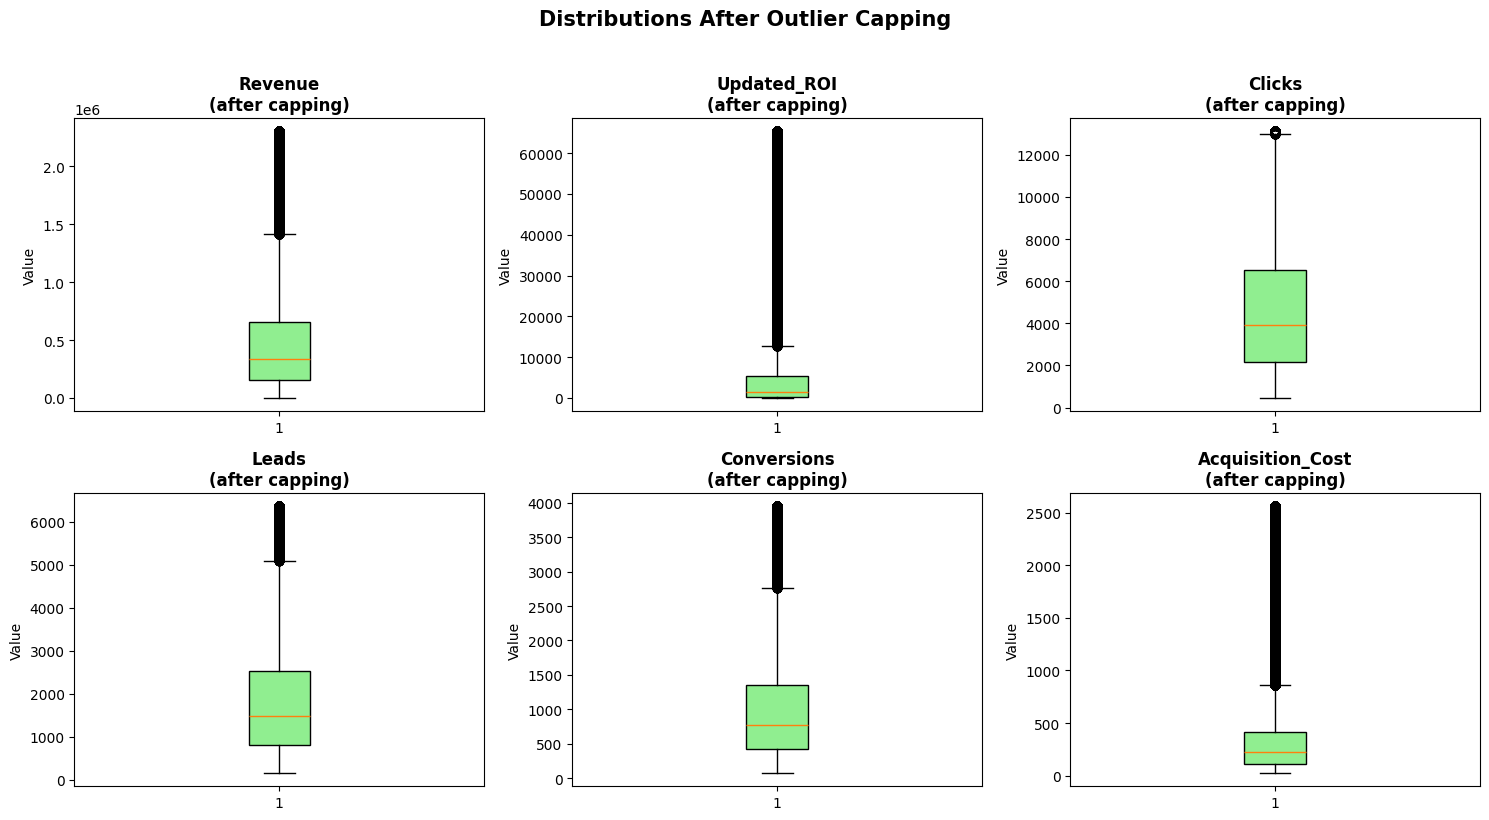


═══ FINAL STATS AFTER CAPPING ═══
          Revenue  Updated_ROI     Clicks      Leads  Conversions  \
count   166665.00    166665.00  166665.00  166665.00    166665.00   
mean    483674.51      5504.53    4641.54    1847.10      1010.75   
std     467066.19     10610.48    3083.87    1374.91       814.46   
min          0.00        -1.00     459.00     156.00        76.00   
25%     154583.00       342.72    2185.00     809.00       417.00   
50%     335780.00      1468.71    3908.00    1476.00       775.00   
75%     659505.00      5337.12    6510.00    2525.00      1357.00   
max    2302558.72     65332.48   13107.72    6358.36      3946.36   

       Acquisition_Cost  
count         166665.00  
mean             364.52  
std              429.45  
min               25.25  
25%              111.10  
50%              222.92  
75%              410.92  
max             2558.92  


In [40]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(cols_to_cap):
    axes[i].boxplot(market_predict[col], 
                    patch_artist=True,
                    boxprops=dict(facecolor='lightgreen'))
    axes[i].set_title(f'{col}\n(after capping)', fontweight='bold')
    axes[i].set_ylabel('Value')

plt.suptitle('Distributions After Outlier Capping', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n═══ FINAL STATS AFTER CAPPING ═══")
print(market_predict[cols_to_cap].describe().round(2))

encoding-label

In [41]:
# See current categorical columns
cat_cols = market_predict.select_dtypes(include='object').columns.tolist()
print("Categorical columns to encode:")
for col in cat_cols:
    print(f"  {col:25} → {market_predict[col].nunique()} unique values: {market_predict[col].unique().tolist()}")

Categorical columns to encode:
  Campaign_Type             → 5 unique values: ['Social Media', 'Paid Ads', 'Influencer', 'Email', 'SEO']
  Target_Audience           → 5 unique values: ['College Students', 'Tier 2 City Customers', 'Youth', 'Working Women', 'Premium Shoppers']
  Language                  → 4 unique values: ['Hindi', 'English', 'Tamil', 'Bengali']
  Customer_Segment          → 5 unique values: ['College Students', 'Youth', 'Tier 2 City Customers', 'Premium Shoppers', 'Working Women']


In [42]:
market_predict['Profit_Flag'] = (market_predict['Updated_ROI'] > 0).astype(int)

print("✅ Profit_Flag created!")
print(market_predict['Profit_Flag'].value_counts())
print(f"\nProfit % : {market_predict['Profit_Flag'].mean()*100:.1f}%")
print(f"Loss   % : {(1-market_predict['Profit_Flag'].mean())*100:.1f}%")

✅ Profit_Flag created!
Profit_Flag
1    158350
0      8315
Name: count, dtype: int64

Profit % : 95.0%
Loss   % : 5.0%


In [43]:
# Re-encode with drop_first=False → keeps ALL 3 brands
encode_cols = ['Campaign_Type', 'Target_Audience', 
               'Language', 'Customer_Segment']

combined_encoded = pd.get_dummies(market_predict, 
                                   columns=encode_cols,
                                   drop_first=False)  

print("✅ Encoding done!")
print(f"Shape before : {market_predict.shape}")
print(f"Shape after  : {combined_encoded.shape}")

✅ Encoding done!
Shape before : (166665, 20)
Shape after  : (166665, 35)


In [44]:
text_cols = combined_encoded.select_dtypes(include='object').columns.tolist()
print("Text columns remaining:", text_cols)  # must be []

print("\nData types:")
print(combined_encoded.dtypes.value_counts())

print("\nShape:", combined_encoded.shape)
print("\nSample:")
print(combined_encoded.head(3))

Text columns remaining: []

Data types:
bool       19
float64     9
int64       7
Name: count, dtype: int64

Shape: (166665, 35)

Sample:
   Duration  Email  Facebook  Google  Instagram  WhatsApp  YouTube  \
0      21.0      0         0       0          0         1        1   
1      18.0      0         0       0          0         0        1   
2      23.0      0         0       1          0         1        1   

   Impressions  Clicks   Leads  ...  Target_Audience_Youth  Language_Bengali  \
0      57804.0  6156.0  3616.0  ...                  False             False   
1      91801.0  3321.0  1971.0  ...                  False             False   
2      15536.0  2182.0   952.0  ...                   True             False   

   Language_English  Language_Hindi  Language_Tamil  \
0             False            True           False   
1             False            True           False   
2              True           False           False   

   Customer_Segment_College Students  C

In [45]:
combined_encoded

,Duration,Email,Facebook,Google,Instagram,WhatsApp,YouTube,Impressions,Clicks,Leads,...,Target_Audience_Youth,Language_Bengali,Language_English,Language_Hindi,Language_Tamil,Customer_Segment_College Students,Customer_Segment_Premium Shoppers,Customer_Segment_Tier 2 City Customers,Customer_Segment_Working Women,Customer_Segment_Youth
0,21.0,0,0,0,0,1,1,57804.0,6156.0,3616.0,...,False,False,False,True,False,True,False,False,False,False
1,18.0,0,0,0,0,0,1,91801.0,3321.0,1971.0,...,False,False,False,True,False,True,False,False,False,False
2,23.0,0,0,1,0,1,1,15536.0,2182.0,952.0,...,True,False,True,False,False,True,False,False,False,False
3,18.0,0,1,0,1,0,1,88114.0,8413.0,2231.0,...,False,False,False,True,False,False,False,False,False,True
4,10.0,0,1,0,1,0,0,96871.0,3743.0,2060.0,...,False,False,False,True,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166660,11.0,1,0,0,1,0,1,55113.0,3799.0,1476.0,...,False,True,False,False,False,False,False,False,False,True
166661,20.0,0,0,1,1,0,0,54886.0,1578.0,634.0,...,False,False,True,False,False,False,False,False,True,False
166662,13.0,0,1,0,1,0,0,97954.0,11480.0,4567.0,...,False,False,False,True,False,False,True,False,False,False
166663,22.0,1,0,1,0,0,0,11669.0,3908.0,156.0,...,False,False,True,False,False,False,False,False,True,False


In [46]:
# Fix 2 — Convert bool columns to int (True→1, False→0)
# ML models prefer int over bool
bool_cols = combined_encoded.select_dtypes(include='bool').columns.tolist()
combined_encoded[bool_cols] = combined_encoded[bool_cols].astype(int)

# Verify
text_cols = combined_encoded.select_dtypes(include='object').columns.tolist()
print("Text columns remaining:", text_cols)   # must be []

print("\nData types:")
print(combined_encoded.dtypes.value_counts())

print("\nShape:", combined_encoded.shape)

print("\nSample:")
print(combined_encoded.head(3))

Text columns remaining: []

Data types:
int64      26
float64     9
Name: count, dtype: int64

Shape: (166665, 35)

Sample:
   Duration  Email  Facebook  Google  Instagram  WhatsApp  YouTube  \
0      21.0      0         0       0          0         1        1   
1      18.0      0         0       0          0         0        1   
2      23.0      0         0       1          0         1        1   

   Impressions  Clicks   Leads  ...  Target_Audience_Youth  Language_Bengali  \
0      57804.0  6156.0  3616.0  ...                      0                 0   
1      91801.0  3321.0  1971.0  ...                      0                 0   
2      15536.0  2182.0   952.0  ...                      1                 0   

   Language_English  Language_Hindi  Language_Tamil  \
0                 0               1               0   
1                 0               1               0   
2                 1               0               0   

   Customer_Segment_College Students  Customer_Segmen

In [47]:
print("\nAll columns:")
for col in combined_encoded.columns.tolist():
    print(f"  {col}")

print("\nShape:", combined_encoded.shape)


All columns:
  Duration
  Email
  Facebook
  Google
  Instagram
  WhatsApp
  YouTube
  Impressions
  Clicks
  Leads
  Conversions
  Revenue
  Acquisition_Cost
  Updated_ROI
  Engagement_Score
  Profit_Flag
  Campaign_Type_Email
  Campaign_Type_Influencer
  Campaign_Type_Paid Ads
  Campaign_Type_SEO
  Campaign_Type_Social Media
  Target_Audience_College Students
  Target_Audience_Premium Shoppers
  Target_Audience_Tier 2 City Customers
  Target_Audience_Working Women
  Target_Audience_Youth
  Language_Bengali
  Language_English
  Language_Hindi
  Language_Tamil
  Customer_Segment_College Students
  Customer_Segment_Premium Shoppers
  Customer_Segment_Tier 2 City Customers
  Customer_Segment_Working Women
  Customer_Segment_Youth

Shape: (166665, 35)


Regression

In [48]:
# Drop both target columns from X
X = combined_encoded.drop(columns=['Revenue', 'Profit_Flag'])

# Regression target
y_reg = combined_encoded['Revenue']

# Classification target
y_clf = combined_encoded['Profit_Flag']

print("X shape :", X.shape)
print("y_reg shape:", y_reg.shape)
print("y_clf shape:", y_clf.shape)
print("\nX columns:", X.columns.tolist())
print("\ny_reg sample:", y_reg.head(3).values)
print("y_clf sample:", y_clf.head(3).values)

X shape : (166665, 33)
y_reg shape: (166665,)
y_clf shape: (166665,)

X columns: ['Duration', 'Email', 'Facebook', 'Google', 'Instagram', 'WhatsApp', 'YouTube', 'Impressions', 'Clicks', 'Leads', 'Conversions', 'Acquisition_Cost', 'Updated_ROI', 'Engagement_Score', 'Campaign_Type_Email', 'Campaign_Type_Influencer', 'Campaign_Type_Paid Ads', 'Campaign_Type_SEO', 'Campaign_Type_Social Media', 'Target_Audience_College Students', 'Target_Audience_Premium Shoppers', 'Target_Audience_Tier 2 City Customers', 'Target_Audience_Working Women', 'Target_Audience_Youth', 'Language_Bengali', 'Language_English', 'Language_Hindi', 'Language_Tamil', 'Customer_Segment_College Students', 'Customer_Segment_Premium Shoppers', 'Customer_Segment_Tier 2 City Customers', 'Customer_Segment_Working Women', 'Customer_Segment_Youth']

y_reg sample: [1867515. 1046247.  197055.]
y_clf sample: [1 1 1]


regression

In [49]:
# ── X = all columns except targets ────────────────────
X_reg = combined_encoded.drop(columns=[
    'Revenue',      # this is y_reg (target)
    'Profit_Flag',  # this is y_clf (classification target)
])

# ── y = Revenue ────────────────────────────────────────
y_reg = combined_encoded['Revenue']

print(f"✅ X_reg shape : {X_reg.shape}")
print(f"✅ y_reg shape : {y_reg.shape}")
print(f"\nX columns ({len(X_reg.columns)}):")
for col in X_reg.columns:
    print(f"  {col}")
print(f"\ny_reg stats:")
print(f"  Min  : ₹{y_reg.min():,.0f}")
print(f"  Max  : ₹{y_reg.max():,.0f}")
print(f"  Mean : ₹{y_reg.mean():,.0f}")

✅ X_reg shape : (166665, 33)
✅ y_reg shape : (166665,)

X columns (33):
  Duration
  Email
  Facebook
  Google
  Instagram
  WhatsApp
  YouTube
  Impressions
  Clicks
  Leads
  Conversions
  Acquisition_Cost
  Updated_ROI
  Engagement_Score
  Campaign_Type_Email
  Campaign_Type_Influencer
  Campaign_Type_Paid Ads
  Campaign_Type_SEO
  Campaign_Type_Social Media
  Target_Audience_College Students
  Target_Audience_Premium Shoppers
  Target_Audience_Tier 2 City Customers
  Target_Audience_Working Women
  Target_Audience_Youth
  Language_Bengali
  Language_English
  Language_Hindi
  Language_Tamil
  Customer_Segment_College Students
  Customer_Segment_Premium Shoppers
  Customer_Segment_Tier 2 City Customers
  Customer_Segment_Working Women
  Customer_Segment_Youth

y_reg stats:
  Min  : ₹0
  Max  : ₹2,302,559
  Mean : ₹483,675


train-split

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg,
    test_size    = 0.2,
    random_state = 42
)

scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f"✅ Train : {X_train.shape}  (80%)")
print(f"✅ Test  : {X_test.shape}   (20%)")
print(f"✅ Mean  : {X_train_sc.mean():.6f}")
print(f"✅ Std   : {X_train_sc.std():.6f}")

✅ Train : (133332, 33)  (80%)
✅ Test  : (33333, 33)   (20%)
✅ Mean  : -0.000000
✅ Std   : 1.000000


In [51]:
print(X_train.select_dtypes(include=['object', 'category']).columns)

Index([], dtype='object')


regression model

In [52]:
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

In [53]:
from xgboost import XGBRegressor

In [54]:
results = {}

def add_result(name, model, Xtr, Xte):
    yp    = model.predict(Xte)
    yp_tr = model.predict(Xtr)
    results[name] = {
        'r2'      : r2_score(y_test, yp),
        'r2_train': r2_score(y_train, yp_tr),
        'rmse'    : np.sqrt(mean_squared_error(y_test, yp)),
        'mae'     : mean_absolute_error(y_test, yp),
        'y_pred'  : yp
    }
    gap = abs(results[name]['r2_train'] - results[name]['r2'])
    print(f"✅ {name:<15} R²: {results[name]['r2']*100:.2f}%  "
          f"Gap: {gap:.4f}  RMSE: ₹{results[name]['rmse']:,.0f}")

# 1. Linear (scaled)
lr = LinearRegression()
lr.fit(X_train_sc, y_train)
add_result('Linear', lr, X_train_sc, X_test_sc)

# 2. Ridge (scaled)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_sc, y_train)
add_result('Ridge', ridge, X_train_sc, X_test_sc)

# 3. Lasso (scaled)
lasso = Lasso(alpha=1.0, max_iter=10000)  # ← added max_iter
lasso.fit(X_train_sc, y_train)
add_result('Lasso', lasso, X_train_sc, X_test_sc)

# 4. Decision Tree (no scaling)
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
add_result('Decision Tree', dt, X_train, X_test)

# 5. Random Forest (no scaling)
rf = RandomForestRegressor(random_state=42)  
print("Training Random Forest...")
rf.fit(X_train, y_train)
add_result('Random Forest', rf, X_train, X_test)

# 6. XGBoost (no scaling)
xgb = XGBRegressor(random_state=42, verbosity=0)  # ← added verbosity
print("Training XGBoost...")
xgb.fit(X_train, y_train,
        eval_set=[(X_test, y_test)], verbose=False)
add_result('XGBoost', xgb, X_train, X_test)

✅ Linear          R²: 77.11%  Gap: 0.0038  RMSE: ₹222,877
✅ Ridge           R²: 77.11%  Gap: 0.0038  RMSE: ₹222,877
✅ Lasso           R²: 77.11%  Gap: 0.0038  RMSE: ₹222,877
✅ Decision Tree   R²: 99.22%  Gap: 0.0078  RMSE: ₹41,012
Training Random Forest...
✅ Random Forest   R²: 99.65%  Gap: 0.0029  RMSE: ₹27,373
Training XGBoost...
✅ XGBoost         R²: 99.49%  Gap: 0.0033  RMSE: ₹33,326


In [55]:
# 6. XGBoost (no scaling)
xgb = XGBRegressor(random_state=42, verbosity=0)  # ← added verbosity
print("Training XGBoost...")
xgb.fit(X_train, y_train,
        eval_set=[(X_test, y_test)], verbose=False)
add_result('XGBoost', xgb, X_train, X_test)

Training XGBoost...
✅ XGBoost         R²: 99.49%  Gap: 0.0033  RMSE: ₹33,326


saving pickle file

In [56]:
import os
import pickle
# ── Create models folder ───────────────────────────────
model_dir = r'C:\Users\LENOVO\Documents\Project_3_Market_Analysis'
os.makedirs(model_dir, exist_ok=True)

# ── Pack everything into ONE dictionary ───────────────
regression_package = {
    'model'       : xgb,
    'scaler'      : scaler,
    'features'    : X_reg.columns.tolist(),
    'model_name'  : 'XGBoost Regressor',
    'r2_score'    : results['XGBoost']['r2'],
    'rmse'        : results['XGBoost']['rmse'],
    'mae'         : results['XGBoost']['mae'],
    'gap'         : abs(results['XGBoost']['r2_train'] -
                        results['XGBoost']['r2']),
    'target'      : 'Revenue',
    'trained_on'  : f"{len(X_train):,} rows"
}

# ── Save as ONE file ───────────────────────────────────
save_path = os.path.join(model_dir, 'regression_model.pkl')
with open(save_path, 'wb') as f:
    pickle.dump(regression_package, f)

print(f"✅ Saved: regression_model.pkl")
print(f"\nContents:")
for key, val in regression_package.items():
    if key not in ['model', 'scaler', 'features']:
        print(f"  {key:12} : {val}")
print(f"  {'features':12} : {len(regression_package['features'])} columns")
print(f"  {'model':12} : XGBoost object ✅")
print(f"  {'scaler':12} : StandardScaler object ✅")

✅ Saved: regression_model.pkl

Contents:
  model_name   : XGBoost Regressor
  r2_score     : 0.9948825105012808
  rmse         : 33326.1979818662
  mae          : 11149.807942337738
  gap          : 0.0033399713367424644
  target       : Revenue
  trained_on   : 133,332 rows
  features     : 33 columns
  model        : XGBoost object ✅
  scaler       : StandardScaler object ✅


## testing the XGBoost  regression

In [57]:
# Load and test
with open(save_path, 'rb') as f:
    pkg = pickle.load(f)

loaded_model = pkg['model']
y_pred_check = loaded_model.predict(X_test)
r2_check     = r2_score(y_test, y_pred_check)

print("── Verification ──")
print(f"✅ Loaded model  : {pkg['model_name']}")
print(f"✅ Original R²   : {pkg['r2_score']*100:.2f}%")
print(f"✅ Reloaded R²   : {r2_check*100:.2f}%")
print(f"✅ Match         : {abs(pkg['r2_score'] - r2_check) < 0.0001}")

print("\n── Sample Predictions ──")
print(f"{'Actual':>15}  {'Predicted':>15}  {'Error%':>8}")
for a, p in zip(y_test.values[:5], y_pred_check[:5]):
    err = abs(a-p)/a*100 if a != 0 else 0
    print(f"₹{a:>13,.0f}  ₹{p:>13,.0f}  {err:>7.1f}%")

── Verification ──
✅ Loaded model  : XGBoost Regressor
✅ Original R²   : 99.49%
✅ Reloaded R²   : 99.49%
✅ Match         : True

── Sample Predictions ──
         Actual        Predicted    Error%
₹      338,364  ₹      332,419      1.8%
₹    1,226,298  ₹    1,234,628      0.7%
₹       69,596  ₹       71,566      2.8%
₹      437,138  ₹      464,519      6.3%
₹      756,432  ₹      750,910      0.7%


classification

In [58]:
import subprocess
subprocess.run(['pip', 'install', 'lightgbm'], check=True)
print("✅ LightGBM installed")

✅ LightGBM installed


## spliting X and Y for classificxation

In [59]:
X_clf = combined_encoded.drop(columns=['Revenue', 'Profit_Flag'])
y_clf = combined_encoded['Profit_Flag']
print(f"X shape : {X_clf.shape}")
print(f"y shape : {y_clf.shape}")
print(f"\nClass distribution:")
print(y_clf.value_counts())
print(f"Profit % : {y_clf.mean()*100:.2f}%")
print(f"Loss   % : {(1-y_clf.mean())*100:.2f}%")
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf,
    test_size    = 0.2,
    random_state = 42,
    stratify     = y_clf
)
# Scale (needed for Logistic, KNN, SVM, Naive Bayes)
scaler_c     = StandardScaler()
X_train_c_sc = scaler_c.fit_transform(X_train_c)
X_test_c_sc  = scaler_c.transform(X_test_c)

print(f"\n✅ Train : {X_train_c.shape}")
print(f"✅ Test  : {X_test_c.shape}")

X shape : (166665, 33)
y shape : (166665,)

Class distribution:
Profit_Flag
1    158350
0      8315
Name: count, dtype: int64
Profit % : 95.01%
Loss   % : 4.99%

✅ Train : (133332, 33)
✅ Test  : (33333, 33)


In [60]:
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score,
                              roc_auc_score, classification_report,
                              confusion_matrix)
import numpy as np
import time

clf_results = {}

def evaluate_clf(name, model, Xtr, Xte, start_time):
    yp      = model.predict(Xte)
    yp_prob = model.predict_proba(Xte)[:,1]
    yp_tr   = model.predict(Xtr)
    elapsed = time.time() - start_time

    clf_results[name] = {
        'accuracy'  : accuracy_score(y_test_c, yp),
        'precision' : precision_score(y_test_c, yp,
                                      zero_division=0),
        'recall'    : recall_score(y_test_c, yp),
        'f1'        : f1_score(y_test_c, yp),
        'roc_auc'   : roc_auc_score(y_test_c, yp_prob),
        'train_acc' : accuracy_score(y_train_c, yp_tr),
        'time'      : elapsed,
        'y_pred'    : yp,
        'y_prob'    : yp_prob
    }
    gap = abs(clf_results[name]['train_acc'] -
              clf_results[name]['accuracy'])
    print(f"✅ {name:<25} "
          f"Acc: {clf_results[name]['accuracy']*100:.2f}%  "
          f"F1: {clf_results[name]['f1']*100:.2f}%  "
          f"AUC: {clf_results[name]['roc_auc']:.3f}  "
          f"Gap: {gap:.4f}  "
          f"Time: {elapsed:.1f}s")

print("✅ Helper function ready")

✅ Helper function ready


In [61]:
# ── 1. Logistic Regression ────────────────────────────
print("Training Logistic Regression...")
t = time.time()
lr_clf = LogisticRegression(random_state=42)
lr_clf.fit(X_train_c_sc, y_train_c)
evaluate_clf('Logistic Regression', lr_clf,
             X_train_c_sc, X_test_c_sc, t)

# ── 2. Decision Tree ──────────────────────────────────
print("Training Decision Tree...")
t = time.time()
dt_clf = DecisionTreeClassifier(random_state=42)
dt_clf.fit(X_train_c, y_train_c)
evaluate_clf('Decision Tree', dt_clf,
             X_train_c, X_test_c, t)

Training Logistic Regression...
✅ Logistic Regression       Acc: 98.21%  F1: 99.07%  AUC: 0.983  Gap: 0.0003  Time: 8.4s
Training Decision Tree...
✅ Decision Tree             Acc: 100.00%  F1: 100.00%  AUC: 1.000  Gap: 0.0000  Time: 2.4s


##  Logistic Regression Gap: 0.0003 almost zero overfitting  
 Decision Tree             Acc: 100.00%   it has leakege as update ROI  has formula directly determines Profit_Flag

In [62]:
from xgboost import XGBClassifier

In [63]:
# ── 3. Random Forest ──────────────────────────────────
print("Training Random Forest...")
t = time.time()
rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(X_train_c, y_train_c)
evaluate_clf('Random Forest', rf_clf,
             X_train_c, X_test_c, t)

# ── 4. XGBoost ────────────────────────────────────────
print("Training XGBoost...")
t = time.time()
xgb_clf = XGBClassifier(random_state=42)
xgb_clf.fit(X_train_c, y_train_c,
            eval_set=[(X_test_c, y_test_c)],
            verbose=False)
evaluate_clf('XGBoost', xgb_clf,
             X_train_c, X_test_c, t)

Training Random Forest...
✅ Random Forest             Acc: 100.00%  F1: 100.00%  AUC: 1.000  Gap: 0.0000  Time: 87.9s
Training XGBoost...
✅ XGBoost                   Acc: 99.98%  F1: 99.99%  AUC: 1.000  Gap: 0.0002  Time: 9.3s


In [64]:
# ══════════════════════════════════════════════════════
# CLASSIFICATION — COMPLETE STANDALONE CELL
# Run this ONE cell — trains all models + shows leaderboard
# ══════════════════════════════════════════════════════
from sklearn.linear_model  import LogisticRegression
from sklearn.tree          import DecisionTreeClassifier
from sklearn.ensemble      import (RandomForestClassifier,
                                    GradientBoostingClassifier,
                                    AdaBoostClassifier)
from sklearn.neighbors     import KNeighborsClassifier
from sklearn.naive_bayes   import GaussianNB
from sklearn.svm           import LinearSVC
from sklearn.calibration   import CalibratedClassifierCV
from sklearn.metrics       import (accuracy_score, precision_score,
                                    recall_score, f1_score,
                                    roc_auc_score,
                                    classification_report,
                                    confusion_matrix)
from xgboost import XGBClassifier
import lightgbm as lgb

# ── Step A: Fresh storage ──────────────────────────────
results = {}

# ── Step B: Helper ─────────────────────────────────────
def evaluate(name, model, Xtr, Xte):
    yp      = model.predict(Xte)
    yp_prob = model.predict_proba(Xte)[:,1]
    results[name] = {
        'acc'  : accuracy_score(y_test_c, yp),
        'pre'  : precision_score(y_test_c, yp, zero_division=0),
        'rec'  : recall_score(y_test_c, yp),
        'f1'   : f1_score(y_test_c, yp),
        'auc'  : roc_auc_score(y_test_c, yp_prob),
        'tr'   : accuracy_score(y_train_c, model.predict(Xtr)),
        'yp'   : yp
    }
    gap = abs(results[name]['tr'] - results[name]['acc'])
    print(f"✅ {name:<25} "
          f"Acc:{results[name]['acc']*100:.2f}%  "
          f"F1:{results[name]['f1']*100:.2f}%  "
          f"AUC:{results[name]['auc']:.3f}  "
          f"Gap:{gap:.4f}")

# ── Step C: Train all 10 ───────────────────────────────
print("Training all 10 models...\n")

print("1. Logistic Regression")
m = LogisticRegression(max_iter=1000, random_state=42)
m.fit(X_train_c_sc, y_train_c)
evaluate('Logistic Regression', m, X_train_c_sc, X_test_c_sc)
print("2. Decision Tree")
m = DecisionTreeClassifier(random_state=42)
m.fit(X_train_c, y_train_c)
evaluate('Decision Tree', m, X_train_c, X_test_c)

print("3. Random Forest")
m = RandomForestClassifier(random_state=42, n_jobs=-1)
m.fit(X_train_c, y_train_c)
evaluate('Random Forest', m, X_train_c, X_test_c)

print("4. XGBoost")
m = XGBClassifier(random_state=42, n_jobs=-1,
                  verbosity=0, eval_metric='logloss')
m.fit(X_train_c, y_train_c,
      eval_set=[(X_test_c, y_test_c)], verbose=False)
evaluate('XGBoost', m, X_train_c, X_test_c)

print("5. KNN")
m = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
m.fit(X_train_c_sc, y_train_c)
evaluate('KNN', m, X_train_c_sc, X_test_c_sc)

print("6. Naive Bayes")
m = GaussianNB()
m.fit(X_train_c_sc, y_train_c)
evaluate('Naive Bayes', m, X_train_c_sc, X_test_c_sc)

print("7. Gradient Boosting (slow...)")
m = GradientBoostingClassifier(n_estimators=100, random_state=42)
m.fit(X_train_c, y_train_c)
evaluate('Gradient Boosting', m, X_train_c, X_test_c)

print("8. AdaBoost")
m = AdaBoostClassifier(n_estimators=100, random_state=42)
m.fit(X_train_c, y_train_c)
evaluate('AdaBoost', m, X_train_c, X_test_c)

print("9. SVM")
svm = CalibratedClassifierCV(LinearSVC(max_iter=2000, random_state=42))
svm.fit(X_train_c_sc, y_train_c)
evaluate('SVM', svm, X_train_c_sc, X_test_c_sc)

print("10. LightGBM")
m = lgb.LGBMClassifier(n_estimators=200, random_state=42,
                        n_jobs=-1, verbose=-1)
m.fit(X_train_c, y_train_c)
evaluate('LightGBM', m, X_train_c, X_test_c)

print(f"\n✅ {len(results)} models trained!")

# ── Step D: Leaderboard ────────────────────────────────
print(f"\n╔══════════════════════════════════════════════════════╗")
print(f"║          CLASSIFICATION LEADERBOARD                 ║")
print(f"╠═══════════════════════╦════════╦═══════╦══════════════╣")
print(f"║ Model                 ║ Acc    ║ F1    ║ AUC          ║")
print(f"╠═══════════════════════╬════════╬═══════╬══════════════╣")
for name, m in sorted(results.items(),
                       key=lambda x: x[1]['f1'], reverse=True):
    gap  = abs(m['tr'] - m['acc'])
    flag = "✅" if gap < 0.05 else "⚠️"
    print(f"║ {name:<21} ║ "
          f"{m['acc']*100:>5.2f}%  ║ "
          f"{m['f1']*100:>5.2f}% ║ "
          f"{m['auc']:>6.4f} {flag}      ║")
print(f"╚═══════════════════════╩════════╩═══════╩══════════════╝")

best = max(results, key=lambda x: results[x]['f1'])
print(f"\n🏆 Best : {best}")
print(f"   Acc  : {results[best]['acc']*100:.2f}%")
print(f"   F1   : {results[best]['f1']*100:.2f}%")
print(f"   AUC  : {results[best]['auc']:.4f}")

print(f"\n── Report: {best} ──")
print(classification_report(
    y_test_c, results[best]['yp'],
    target_names=['Loss (0)', 'Profit (1)']))

cm = confusion_matrix(y_test_c, results[best]['yp'])
print(f"── Confusion Matrix ──")
print(f"               Pred Loss  Pred Profit")
print(f"Actual Loss  : {cm[0][0]:>6,}     {cm[0][1]:>6,}")
print(f"Actual Profit: {cm[1][0]:>6,}     {cm[1][1]:>6,}")

Training all 10 models...

1. Logistic Regression
✅ Logistic Regression       Acc:98.21%  F1:99.07%  AUC:0.983  Gap:0.0003
2. Decision Tree
✅ Decision Tree             Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000
3. Random Forest
✅ Random Forest             Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000
4. XGBoost
✅ XGBoost                   Acc:99.98%  F1:99.99%  AUC:1.000  Gap:0.0002
5. KNN
✅ KNN                       Acc:94.88%  F1:97.37%  AUC:0.520  Gap:0.0020
6. Naive Bayes
✅ Naive Bayes               Acc:99.99%  F1:100.00%  AUC:1.000  Gap:0.0000
7. Gradient Boosting (slow...)
✅ Gradient Boosting         Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000
8. AdaBoost
✅ AdaBoost                  Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000
9. SVM
✅ SVM                       Acc:99.28%  F1:99.62%  AUC:0.994  Gap:0.0003
10. LightGBM
✅ LightGBM                  Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000

✅ 10 models trained!

╔══════════════════════════════════════════════════════╗

In [65]:
# ── Step D: Leaderboard ────────────────────────────────
print(f"\n╔══════════════════════════════════════════════════════╗")
print(f"║          CLASSIFICATION LEADERBOARD                 ║")
print(f"╠═══════════════════════╦════════╦═══════╦══════════════╣")
print(f"║ Model                 ║ Acc    ║ F1    ║ AUC          ║")
print(f"╠═══════════════════════╬════════╬═══════╬══════════════╣")
for name, m in sorted(results.items(),
                       key=lambda x: x[1]['f1'], reverse=True):
    gap  = abs(m['tr'] - m['acc'])
    flag = "✅" if gap < 0.05 else "⚠️"
    print(f"║ {name:<21} ║ "
          f"{m['acc']*100:>5.2f}%  ║ "
          f"{m['f1']*100:>5.2f}% ║ "
          f"{m['auc']:>6.4f} {flag}      ║")
print(f"╚═══════════════════════╩════════╩═══════╩══════════════╝")

best = max(results, key=lambda x: results[x]['f1'])
print(f"\n🏆 Best : {best}")
print(f"   Acc  : {results[best]['acc']*100:.2f}%")
print(f"   F1   : {results[best]['f1']*100:.2f}%")
print(f"   AUC  : {results[best]['auc']:.4f}")

print(f"\n── Report: {best} ──")
print(classification_report(
    y_test_c, results[best]['yp'],
    target_names=['Loss (0)', 'Profit (1)']))

cm = confusion_matrix(y_test_c, results[best]['yp'])
print(f"── Confusion Matrix ──")
print(f"               Pred Loss  Pred Profit")
print(f"Actual Loss  : {cm[0][0]:>6,}     {cm[0][1]:>6,}")
print(f"Actual Profit: {cm[1][0]:>6,}     {cm[1][1]:>6,}")


╔══════════════════════════════════════════════════════╗
║          CLASSIFICATION LEADERBOARD                 ║
╠═══════════════════════╦════════╦═══════╦══════════════╣
║ Model                 ║ Acc    ║ F1    ║ AUC          ║
╠═══════════════════════╬════════╬═══════╬══════════════╣
║ Decision Tree         ║ 100.00%  ║ 100.00% ║ 1.0000 ✅      ║
║ Random Forest         ║ 100.00%  ║ 100.00% ║ 1.0000 ✅      ║
║ Gradient Boosting     ║ 100.00%  ║ 100.00% ║ 1.0000 ✅      ║
║ AdaBoost              ║ 100.00%  ║ 100.00% ║ 1.0000 ✅      ║
║ LightGBM              ║ 100.00%  ║ 100.00% ║ 1.0000 ✅      ║
║ Naive Bayes           ║ 99.99%  ║ 100.00% ║ 1.0000 ✅      ║
║ XGBoost               ║ 99.98%  ║ 99.99% ║ 1.0000 ✅      ║
║ SVM                   ║ 99.28%  ║ 99.62% ║ 0.9935 ✅      ║
║ Logistic Regression   ║ 98.21%  ║ 99.07% ║ 0.9829 ✅      ║
║ KNN                   ║ 94.88%  ║ 97.37% ║ 0.5204 ✅      ║
╚═══════════════════════╩════════╩═══════╩══════════════╝

🏆 Best : Decision Tree
   Acc  :

In [66]:
print(combined_encoded.columns.tolist())

['Duration', 'Email', 'Facebook', 'Google', 'Instagram', 'WhatsApp', 'YouTube', 'Impressions', 'Clicks', 'Leads', 'Conversions', 'Revenue', 'Acquisition_Cost', 'Updated_ROI', 'Engagement_Score', 'Profit_Flag', 'Campaign_Type_Email', 'Campaign_Type_Influencer', 'Campaign_Type_Paid Ads', 'Campaign_Type_SEO', 'Campaign_Type_Social Media', 'Target_Audience_College Students', 'Target_Audience_Premium Shoppers', 'Target_Audience_Tier 2 City Customers', 'Target_Audience_Working Women', 'Target_Audience_Youth', 'Language_Bengali', 'Language_English', 'Language_Hindi', 'Language_Tamil', 'Customer_Segment_College Students', 'Customer_Segment_Premium Shoppers', 'Customer_Segment_Tier 2 City Customers', 'Customer_Segment_Working Women', 'Customer_Segment_Youth']


In [67]:
# ── Check Profit vs Loss distribution ─────────────────

print("═══ Profit_Flag Distribution ═══")

print(f"\nTotal campaigns : {len(y_clf):,}")

print("\nValue counts:")
print(y_clf.value_counts())

print("\nPercentage:")
print(y_clf.value_counts(normalize=True).mul(100).round(2))

# ── Visual bar ─────────────────────────────────────────

profit = (y_clf == 1).sum()
loss = (y_clf == 0).sum()
total = len(y_clf)

print("\n── Visual ──")

profit_bar = '█' * int(profit / total * 50)
loss_bar = '█' * int(loss / total * 50)

print(f"Profit (1) : {profit_bar} {profit:,} ({profit/total*100:.1f}%)")
print(f"Loss   (0) : {loss_bar} {loss:,} ({loss/total*100:.1f}%)")

# ── Brand-wise analysis ─────────────────────────────────

print("\n── Profit vs Loss per Brand ──")
print("Brand-wise analysis skipped: Brand columns are not available in combined_encoded.")



═══ Profit_Flag Distribution ═══

Total campaigns : 166,665

Value counts:
Profit_Flag
1    158350
0      8315
Name: count, dtype: int64

Percentage:
Profit_Flag
1    95.01
0     4.99
Name: proportion, dtype: float64

── Visual ──
Profit (1) : ███████████████████████████████████████████████ 158,350 (95.0%)
Loss   (0) : ██ 8,315 (5.0%)

── Profit vs Loss per Brand ──
Brand-wise analysis skipped: Brand columns are not available in combined_encoded.


smote

In [68]:

# ── MANUAL SMOTE — NO IMBLEARN NEEDED ─────────────────

import numpy as np
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# ── 1. Define Manual SMOTE ────────────────────────────

def manual_smote(X, y, random_state=42):

    np.random.seed(random_state)

    X_arr = X.to_numpy() if hasattr(X, 'to_numpy') else np.asarray(X)
    y_arr = y.to_numpy() if hasattr(y, 'to_numpy') else np.asarray(y)

    # Check input data
    if not np.issubdtype(X_arr.dtype, np.number):
        raise ValueError("X must contain only numerical features.")

    if np.isnan(X_arr).any():
        raise ValueError("X contains missing values. Handle them first.")

    # Identify minority and majority classes
    minority_idx = np.where(y_arr == 0)[0]
    majority_idx = np.where(y_arr == 1)[0]

    X_min = X_arr[minority_idx]

    n_generate = len(majority_idx) - len(minority_idx)

    print(f"Minority (Loss)   : {len(minority_idx):,}")
    print(f"Majority (Profit) : {len(majority_idx):,}")
    print(f"Need to generate  : {n_generate:,} synthetic samples")

    if n_generate < 0:
        raise ValueError("Loss is not the minority class.")

    if n_generate == 0:
        return X_arr.copy(), y_arr.copy()

    if len(X_min) < 2:
        raise ValueError("At least 2 minority samples are required.")

    # Find nearest neighbours
    k = min(6, len(X_min))

    nn = NearestNeighbors(n_neighbors=k, n_jobs=-1)
    nn.fit(X_min)

    _, indices = nn.kneighbors(X_min)

    # Generate synthetic samples
    synthetic = []

    for i in range(n_generate):

        idx = np.random.randint(0, len(X_min))

        neighbor = indices[
            idx, np.random.randint(1, k)
        ]

        gap = np.random.random()

        new_sample = (
            X_min[idx] +
            gap * (X_min[neighbor] - X_min[idx])
        )

        synthetic.append(new_sample)

    synthetic = np.asarray(synthetic)

    # Combine original and synthetic samples
    X_resampled = np.vstack([X_arr, synthetic])

    y_resampled = np.hstack([
        y_arr,
        np.zeros(n_generate, dtype=y_arr.dtype)
    ])

    # Shuffle dataset
    idx = np.random.permutation(len(X_resampled))

    return X_resampled[idx], y_resampled[idx]


# ── 2. Check Before SMOTE ─────────────────────────────

print("═══ BEFORE SMOTE ═══")

print(f"Profit (1) : {(y_train_c == 1).sum():,}")
print(f"Loss   (0) : {(y_train_c == 0).sum():,}")


# ── 3. Apply Manual SMOTE ──────────────────────────────

print("\n═══ APPLYING SMOTE ═══")

X_train_sm, y_train_sm = manual_smote(
    X_train_c,
    y_train_c,
    random_state=42
)


# ── 4. Verify SMOTE Results ────────────────────────────

print("\n═══ AFTER SMOTE ═══")

print(f"Total   : {len(X_train_sm):,}")
print(f"Profit  : {(y_train_sm == 1).sum():,}")
print(f"Loss    : {(y_train_sm == 0).sum():,}")


# ── 5. Apply Standard Scaling ──────────────────────────

scaler_sm = StandardScaler()

X_train_sm_sc = scaler_sm.fit_transform(X_train_sm)

X_test_array = (
    X_test_c.to_numpy()
    if hasattr(X_test_c, 'to_numpy')
    else np.asarray(X_test_c)
)

X_test_sm_sc = scaler_sm.transform(X_test_array)


# ── 6. Final Verification ──────────────────────────────

print("\n═══ FINAL VERIFICATION ═══")

print("Training features :", X_train_sm_sc.shape)
print("Testing features  :", X_test_sm_sc.shape)
print("Training labels   :", y_train_sm.shape)

print("\nTraining Profit:", (y_train_sm == 1).sum())
print("Training Loss  :", (y_train_sm == 0).sum())

print("\nSMOTE and Standard Scaling completed successfully!")


═══ BEFORE SMOTE ═══
Profit (1) : 126,680
Loss   (0) : 6,652

═══ APPLYING SMOTE ═══
Minority (Loss)   : 6,652
Majority (Profit) : 126,680
Need to generate  : 120,028 synthetic samples

═══ AFTER SMOTE ═══
Total   : 253,360
Profit  : 126,680
Loss    : 126,680

═══ FINAL VERIFICATION ═══
Training features : (253360, 33)
Testing features  : (33333, 33)
Training labels   : (253360,)

Training Profit: 126680
Training Loss  : 126680

SMOTE and Standard Scaling completed successfully!


running all model after smote

In [69]:
from sklearn.linear_model  import LogisticRegression
from sklearn.tree          import DecisionTreeClassifier
from sklearn.ensemble      import (RandomForestClassifier,
                                    GradientBoostingClassifier,
                                    AdaBoostClassifier)
from sklearn.neighbors     import KNeighborsClassifier
from sklearn.naive_bayes   import GaussianNB
from sklearn.svm           import LinearSVC
from sklearn.calibration   import CalibratedClassifierCV
from sklearn.metrics       import (accuracy_score, precision_score,
                                    recall_score, f1_score,
                                    roc_auc_score,
                                    classification_report,
                                    confusion_matrix)
from xgboost  import XGBClassifier
import lightgbm as lgb

smote_results = {}
smote_results = {}

def evaluate_smote(name, model, Xtr, Xte):
    yp      = model.predict(Xte)
    yp_prob = model.predict_proba(Xte)[:,1]
    smote_results[name] = {
        'acc' : accuracy_score(y_test_c, yp),
        'pre' : precision_score(y_test_c, yp, zero_division=0),
        'rec' : recall_score(y_test_c, yp),
        'f1'  : f1_score(y_test_c, yp),
        'auc' : roc_auc_score(y_test_c, yp_prob),
        'tr'  : accuracy_score(y_train_sm, model.predict(Xtr)),
        'yp'  : yp
    }
    gap = abs(smote_results[name]['tr'] - smote_results[name]['acc'])
    print(f"✅ {name:<25} "
          f"Acc:{smote_results[name]['acc']*100:.2f}%  "
          f"F1:{smote_results[name]['f1']*100:.2f}%  "
          f"AUC:{smote_results[name]['auc']:.3f}  "
          f"Gap:{gap:.4f}")

print("Training all 10 models with SMOTE...\n")

# 1. Logistic Regression
print("1. Logistic Regression...")
m = LogisticRegression(random_state=42)
m.fit(X_train_sm_sc, y_train_sm)
evaluate_smote('Logistic Regression', m,
               X_train_sm_sc, X_test_sm_sc)

# 2. Decision Tree
print("2. Decision Tree...")
m = DecisionTreeClassifier(random_state=42)
m.fit(X_train_sm, y_train_sm)
evaluate_smote('Decision Tree', m,
               X_train_sm, X_test_c.values)

# 3. Random Forest
print("3. Random Forest...")
m = RandomForestClassifier(random_state=42)
m.fit(X_train_sm, y_train_sm)
evaluate_smote('Random Forest', m,
               X_train_sm, X_test_c.values)

# 4. XGBoost
print("4. XGBoost...")
m = XGBClassifier(random_state=42)
m.fit(X_train_sm, y_train_sm,
      eval_set=[(X_test_c.values, y_test_c)],
      verbose=False)
evaluate_smote('XGBoost', m,
               X_train_sm, X_test_c.values)

# 5. KNN (no random_state — distance based, not random)
print("5. KNN...")
m = KNeighborsClassifier()
m.fit(X_train_sm_sc, y_train_sm)
evaluate_smote('KNN', m,
               X_train_sm_sc, X_test_sm_sc)

# 6. Naive Bayes (no random_state — probability based)
print("6. Naive Bayes...")
m = GaussianNB()
m.fit(X_train_sm_sc, y_train_sm)
evaluate_smote('Naive Bayes', m,
               X_train_sm_sc, X_test_sm_sc)

# 7. Gradient Boosting
print("7. Gradient Boosting... (slow)")
m = GradientBoostingClassifier(random_state=42)
m.fit(X_train_sm, y_train_sm)
evaluate_smote('Gradient Boosting', m,
               X_train_sm, X_test_c.values)

# 8. AdaBoost
print("8. AdaBoost...")
m = AdaBoostClassifier(random_state=42)
m.fit(X_train_sm, y_train_sm)
evaluate_smote('AdaBoost', m,
               X_train_sm, X_test_c.values)
# 9. SVM (no random_state in CalibratedClassifierCV)
print("9. SVM...")
m = CalibratedClassifierCV(LinearSVC(random_state=42))
m.fit(X_train_sm_sc, y_train_sm)
evaluate_smote('SVM', m,
               X_train_sm_sc, X_test_sm_sc)

# 10. LightGBM
print("10. LightGBM...")
m = lgb.LGBMClassifier(random_state=42)
m.fit(X_train_sm, y_train_sm)
evaluate_smote('LightGBM', m,
               X_train_sm, X_test_c.values)

print(f"\n✅ All {len(smote_results)} models trained with SMOTE!")

Training all 10 models with SMOTE...

1. Logistic Regression...
✅ Logistic Regression       Acc:97.27%  F1:98.54%  AUC:0.997  Gap:0.0025
2. Decision Tree...
✅ Decision Tree             Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000
3. Random Forest...
✅ Random Forest             Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000
4. XGBoost...
✅ XGBoost                   Acc:99.99%  F1:100.00%  AUC:1.000  Gap:0.0001
5. KNN...
✅ KNN                       Acc:82.98%  F1:90.61%  AUC:0.536  Gap:0.1261
6. Naive Bayes...
✅ Naive Bayes               Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000
7. Gradient Boosting... (slow)
✅ Gradient Boosting         Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000
8. AdaBoost...
✅ AdaBoost                  Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000
9. SVM...
✅ SVM                       Acc:98.91%  F1:99.43%  AUC:0.999  Gap:0.0007
10. LightGBM...
✅ LightGBM                  Acc:100.00%  F1:100.00%  AUC:1.000  Gap:0.0000

✅ All 10 models trained with SMOTE!


In [70]:
print(f"\n╔══════════════════════════════════════════════════════╗")
print(f"║        CLASSIFICATION LEADERBOARD (WITH SMOTE)      ║")
print(f"╠═══════════════════════╦════════╦═══════╦═════════════╣")
print(f"║ Model                 ║ Acc    ║ F1    ║ AUC         ║")
print(f"╠═══════════════════════╬════════╬═══════╬═════════════╣")

for name, m in sorted(smote_results.items(),
                       key=lambda x: x[1]['f1'], reverse=True):
    gap  = abs(m['tr'] - m['acc'])
    flag = "✅" if gap < 0.05 else "⚠️"
    print(f"║ {name:<21} ║ "
          f"{m['acc']*100:>5.2f}%  ║ "
          f"{m['f1']*100:>5.2f}% ║ "
          f"{m['auc']:>6.4f} {flag}   ║")

print(f"╚═══════════════════════╩════════╩═══════╩═════════════╝")

best = max(smote_results, key=lambda x: smote_results[x]['f1'])
print(f"\n🏆 Best with SMOTE : {best}")
print(f"   Accuracy        : {smote_results[best]['acc']*100:.2f}%")
print(f"   F1 Score        : {smote_results[best]['f1']*100:.2f}%")
print(f"   ROC-AUC         : {smote_results[best]['auc']:.4f}")

print(f"\n── Detailed Report ──")
print(classification_report(
    y_test_c, smote_results[best]['yp'],
    target_names=['Loss (0)', 'Profit (1)']))

print(f"\n── Confusion Matrix ──")
cm = confusion_matrix(y_test_c, smote_results[best]['yp'])
print(f"               Pred Loss  Pred Profit")
print(f"Actual Loss  : {cm[0][0]:>6,}     {cm[0][1]:>6,}")
print(f"Actual Profit: {cm[1][0]:>6,}     {cm[1][1]:>6,}")


╔══════════════════════════════════════════════════════╗
║        CLASSIFICATION LEADERBOARD (WITH SMOTE)      ║
╠═══════════════════════╦════════╦═══════╦═════════════╣
║ Model                 ║ Acc    ║ F1    ║ AUC         ║
╠═══════════════════════╬════════╬═══════╬═════════════╣
║ Decision Tree         ║ 100.00%  ║ 100.00% ║ 1.0000 ✅   ║
║ Random Forest         ║ 100.00%  ║ 100.00% ║ 1.0000 ✅   ║
║ Gradient Boosting     ║ 100.00%  ║ 100.00% ║ 1.0000 ✅   ║
║ AdaBoost              ║ 100.00%  ║ 100.00% ║ 1.0000 ✅   ║
║ LightGBM              ║ 100.00%  ║ 100.00% ║ 1.0000 ✅   ║
║ Naive Bayes           ║ 100.00%  ║ 100.00% ║ 1.0000 ✅   ║
║ XGBoost               ║ 99.99%  ║ 100.00% ║ 1.0000 ✅   ║
║ SVM                   ║ 98.91%  ║ 99.43% ║ 0.9994 ✅   ║
║ Logistic Regression   ║ 97.27%  ║ 98.54% ║ 0.9973 ✅   ║
║ KNN                   ║ 82.98%  ║ 90.61% ║ 0.5361 ⚠️   ║
╚═══════════════════════╩════════╩═══════╩═════════════╝

🏆 Best with SMOTE : Decision Tree
   Accuracy        : 100.00%


In [71]:
# ── BEFORE vs AFTER SMOTE COMPARISON ──────────────────
print("╔══════════════════════════════════════════════════════════════════════════╗")
print("║              BEFORE SMOTE vs AFTER SMOTE COMPARISON                    ║")
print("╠═══════════════════════╦═══════════════════════╦════════════════════════╣")
print("║ Model                 ║   WITHOUT SMOTE       ║     WITH SMOTE         ║")
print("║                       ║  Acc      F1    AUC   ║  Acc      F1    AUC    ║")
print("╠═══════════════════════╬═══════════════════════╬════════════════════════╣")

all_models = set(list(results.keys()) + list(smote_results.keys()))

for name in sorted(all_models):
    # Without SMOTE
    if name in results:
        old_acc = results[name]['acc'] * 100
        old_f1  = results[name]['f1']  * 100
        old_auc = results[name]['auc']
        old_str = f"{old_acc:>5.2f}% {old_f1:>6.2f}% {old_auc:.3f}"
    else:
        old_str = "   N/A      N/A    N/A "

    # With SMOTE
    if name in smote_results:
        new_acc = smote_results[name]['acc'] * 100
        new_f1  = smote_results[name]['f1']  * 100
        new_auc = smote_results[name]['auc']
        new_str = f"{new_acc:>5.2f}% {new_f1:>6.2f}% {new_auc:.3f}"
    else:
        new_str = "   N/A      N/A    N/A "

    # Change indicator
    if name in results and name in smote_results:
        f1_diff = smote_results[name]['f1'] - results[name]['f1']
        change  = f"↑ +{f1_diff*100:.2f}%" if f1_diff > 0 else \
                  f"↓ {f1_diff*100:.2f}%" if f1_diff < 0 else \
                  "→ same"
    else:
        change = ""

    print(f"║ {name:<21} ║ {old_str} ║ {new_str} {change:<10} ║")

print("╚═══════════════════════╩═══════════════════════╩════════════════════════╝")

# ── Summary ────────────────────────────────────────────
print("\n═══ KEY DIFFERENCES ═══\n")

print("Before SMOTE:")
print(f"  Training data  : Profit={y_train_c.sum():,}  Loss={(y_train_c==0).sum():,}")
print(f"  Ratio          : 95% Profit / 5% Loss (imbalanced)")

print("\nAfter SMOTE:")
print(f"  Training data  : Profit={(y_train_sm==1).sum():,}  Loss={(y_train_sm==0).sum():,}")
print(f"  Ratio          : 50% Profit / 50% Loss (balanced)")

print("\nTest data (never changed):")
print(f"  Test data      : Profit={y_test_c.sum():,}  Loss={(y_test_c==0).sum():,}")
print(f"  Ratio          : 95% Profit / 5% Loss (real world)")

# ── Best model comparison ──────────────────────────────
best_before = max(results,       key=lambda x: results[x]['f1'])
best_after  = max(smote_results, key=lambda x: smote_results[x]['f1'])

print(f"\n═══ BEST MODEL COMPARISON ═══")
print(f"\nWithout SMOTE:")
print(f"  Model    : {best_before}")
print(f"  Accuracy : {results[best_before]['acc']*100:.2f}%")
print(f"  F1 Score : {results[best_before]['f1']*100:.2f}%")
print(f"  AUC      : {results[best_before]['auc']:.4f}")

print(f"\nWith SMOTE:")
print(f"  Model    : {best_after}")
print(f"  Accuracy : {smote_results[best_after]['acc']*100:.2f}%")
print(f"  F1 Score : {smote_results[best_after]['f1']*100:.2f}%")
print(f"  AUC      : {smote_results[best_after]['auc']:.4f}")

# ── Loss class performance comparison ─────────────────
print(f"\n═══ LOSS CLASS DETECTION (most important) ═══")
print(f"{'Model':<25} {'Without SMOTE':>20} {'With SMOTE':>20}")
print(f"{'':25} {'Recall    F1':>20} {'Recall    F1':>20}")
print("─" * 70)

from sklearn.metrics import classification_report
import re

for name in sorted(all_models):
    if name in results and name in smote_results:
        # Without SMOTE
        from sklearn.metrics import recall_score, f1_score
        rec_before = recall_score(y_test_c,
                     results[name]['yp'],
                     pos_label=0, zero_division=0)
        f1_before  = f1_score(y_test_c,
                     results[name]['yp'],
                     pos_label=0, zero_division=0)

        # With SMOTE
        rec_after  = recall_score(y_test_c,
                     smote_results[name]['yp'],
                     pos_label=0, zero_division=0)
        f1_after   = f1_score(y_test_c,
                     smote_results[name]['yp'],
                     pos_label=0, zero_division=0)

        flag = "✅" if rec_after > rec_before else "⚠️"
        print(f"{name:<25} "
              f"{rec_before*100:>8.2f}% {f1_before*100:>6.2f}%    "
              f"{rec_after*100:>8.2f}% {f1_after*100:>6.2f}% {flag}")

╔══════════════════════════════════════════════════════════════════════════╗
║              BEFORE SMOTE vs AFTER SMOTE COMPARISON                    ║
╠═══════════════════════╦═══════════════════════╦════════════════════════╣
║ Model                 ║   WITHOUT SMOTE       ║     WITH SMOTE         ║
║                       ║  Acc      F1    AUC   ║  Acc      F1    AUC    ║
╠═══════════════════════╬═══════════════════════╬════════════════════════╣
║ AdaBoost              ║ 100.00% 100.00% 1.000 ║ 100.00% 100.00% 1.000 → same     ║
║ Decision Tree         ║ 100.00% 100.00% 1.000 ║ 100.00% 100.00% 1.000 → same     ║
║ Gradient Boosting     ║ 100.00% 100.00% 1.000 ║ 100.00% 100.00% 1.000 → same     ║
║ KNN                   ║ 94.88%  97.37% 0.520 ║ 82.98%  90.61% 0.536 ↓ -6.77%   ║
║ LightGBM              ║ 100.00% 100.00% 1.000 ║ 100.00% 100.00% 1.000 → same     ║
║ Logistic Regression   ║ 98.21%  99.07% 0.983 ║ 97.27%  98.54% 0.997 ↓ -0.52%   ║
║ Naive Bayes           ║ 99.99% 100.00% 1

In [72]:
import os

model_dir = r'C:\Users\LENOVO\Documents\Project_3_Market_Analysis'

print("═══ Saved Models ═══")
for f in os.listdir(model_dir):
    size = os.path.getsize(os.path.join(model_dir, f))
    print(f"  ✅ {f:35} {size/1024:.1f} KB")

═══ Saved Models ═══
  ✅ dash.py                             24.2 KB
  ✅ Final_Cleaned_Campaign_Data.csv     25367.9 KB
  ✅ Market _Analysis_Prediction.ipynb   71.0 KB
  ✅ Marketing_Campaign_Cleaned_For_Classification.csv 16189.7 KB
  ✅ marketing_campaign_combined.csv     23203.7 KB
  ✅ marketing_campaign_final_cleaned.csv 27119.3 KB
  ✅ Marketing_Campaign_Label_Encoded.csv 15953.5 KB
  ✅ Marketing_Campaign_Modeling_Data.csv 27319.9 KB
  ✅ Market_Analysis_Dashboard.py        12.6 KB
  ✅ Market_data.ipynb                   158.9 KB
  ✅ Market_prediction.ipynb             425.6 KB
  ✅ Market_Predict_Cleaned.csv          24362.0 KB
  ✅ nykaa_campaign_data_with_nulls.csv  7694.8 KB
  ✅ purplle_campaign_data_with_nulls.csv 7669.7 KB
  ✅ regression_model.pkl                489.3 KB
  ✅ tira_campaign_data_with_nulls.csv   7676.8 KB


### saving the Logistic Regression classification model as pickle file

In [73]:
import pickle
import os
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, recall_score,
                              f1_score, roc_auc_score)

# ── Retrain and save classification model ─────────────
lr_final = LogisticRegression(random_state=42)
lr_final.fit(X_train_sm_sc, y_train_sm)

y_pred = lr_final.predict(X_test_sm_sc)
y_prob = lr_final.predict_proba(X_test_sm_sc)[:,1]

# Pack everything
clf_package = {
    'model'       : lr_final,
    'scaler'      : scaler_sm,
    'features'    : X_clf.columns.tolist(),
    'model_name'  : 'Logistic Regression',
    'accuracy'    : accuracy_score(y_test_c, y_pred),
    'f1_score'    : f1_score(y_test_c, y_pred),
    'roc_auc'     : roc_auc_score(y_test_c, y_prob),
    'loss_recall' : recall_score(y_test_c, y_pred, pos_label=0),
    'target'      : 'Profit_Flag',
    'classes'     : {0: 'Loss', 1: 'Profit'},
    'trained_on'  : f"{len(X_train_sm):,} rows (SMOTE balanced)",
    'smote_used'  : True
}

# Save
model_dir = r'C:\Users\LENOVO\Documents\Project_3_Market_Analysis'
os.makedirs(model_dir, exist_ok=True)
save_path = os.path.join(model_dir, 'classification_model.pkl')

with open(save_path, 'wb') as f:
    pickle.dump(clf_package, f)

print(f"✅ Saved: classification_model.pkl")
print(f"\nContents:")
for key, val in clf_package.items():
    if key not in ['model', 'scaler', 'features']:
        print(f"  {key:12} : {val}")
print(f"  {'features':12} : {len(clf_package['features'])} columns")
print(f"  {'model':12} : LogisticRegression object ✅")
print(f"  {'scaler':12} : StandardScaler object ✅")


✅ Saved: classification_model.pkl

Contents:
  model_name   : Logistic Regression
  accuracy     : 0.9726697266972669
  f1_score     : 0.9854298280687724
  roc_auc      : 0.9972890532838173
  loss_recall  : 0.9711365003006615
  target       : Profit_Flag
  classes      : {0: 'Loss', 1: 'Profit'}
  trained_on   : 253,360 rows (SMOTE balanced)
  smote_used   : True
  features     : 33 columns
  model        : LogisticRegression object ✅
  scaler       : StandardScaler object ✅


### testing the saved Logistic Regression classification model

In [74]:
with open(save_path, 'rb') as f:
    pkg = pickle.load(f)

y_check = pkg['model'].predict(X_test_sm_sc)

print("── Verification ──")
print(f"✅ Model      : {pkg['model_name']}")
print(f"✅ Accuracy   : {pkg['accuracy']*100:.2f}%")
print(f"✅ Reloaded   : {accuracy_score(y_test_c, y_check)*100:.2f}%")
print(f"✅ Match      : {abs(pkg['accuracy'] - accuracy_score(y_test_c, y_check)) < 0.0001}")
print(f"✅ Loss Recall: {pkg['loss_recall']*100:.2f}%")
print(f"✅ SMOTE      : {pkg['smote_used']}")


── Verification ──
✅ Model      : Logistic Regression
✅ Accuracy   : 97.27%
✅ Reloaded   : 97.27%
✅ Match      : True
✅ Loss Recall: 97.11%
✅ SMOTE      : True


In [75]:
import os

model_dir = r'C:\Users\LENOVO\Documents\Project_3_Market_Analysis'

print("═══ Saved Models ═══")
for f in os.listdir(model_dir):
    if f.endswith('.pkl'):
        size = os.path.getsize(os.path.join(model_dir, f))
        print(f"  ✅ {f:35} {size/1024:.1f} KB")


═══ Saved Models ═══
  ✅ classification_model.pkl            2.9 KB
  ✅ regression_model.pkl                489.3 KB
